# Proyecto 8 — Análisis Exploratorio de Datos (EDA): Inclusión Financiera (Global Findex 2025)

**Autora:** Lena (Análisis exploratorio, visualización y negocio)  
**Equipo:** Lena, Tania, Franco  
**Dataset:** Global Findex 2025 (`data/raw/findex_microdata_2025_labelled_update112425.csv`)  
**Variable objetivo (`target`):** `account` (`1` = tiene cuenta financiera o de dinero móvil; `0` = no tiene cuenta / no bancarizado)

## Objetivo del análisis
1. Comprender la estructura, calidad y codificación real de los microdatos de Global Findex 2025.
2. Analizar la distribución del target (`account`), los valores nulos por columna y las distribuciones numéricas.
3. Identificar qué variables generan **data leakage** (fuga de datos) para cerrar la lista de columnas válidas en la Fase 0 y guiar `src/preprocess.py`.
4. Explorar cómo varía la exclusión financiera según género, ingreso, educación, empleo, edad, conectividad digital y geografía.
5. Extraer **insights de negocio accionables** sobre los perfiles no bancarizados para orientar campañas de inclusión financiera.

> **Convenciones del equipo:** `random_state = 42`, split estratificado 80/20 en `src/preprocess.py`, evaluación centrada en F1, Recall y ROC-AUC debido al desbalance moderado, y objetivo de overfitting < 5%.


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 100,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

COLOR_ACC = "#1f6f8b"     # Con cuenta (account = 1)
COLOR_UNB = "#d95f02"     # Sin cuenta (account = 0)
COLOR_NEUTRAL = "#4c566a"

# Funciona tanto si se ejecuta desde notebooks/ como desde la raiz del repo
ruta_candidata_1 = Path("../data/raw/findex_microdata_2025_labelled_update112425.csv")
ruta_candidata_2 = Path("data/raw/findex_microdata_2025_labelled_update112425.csv")
DATA_PATH = ruta_candidata_1 if ruta_candidata_1.exists() else ruta_candidata_2
assert DATA_PATH.exists(), f"No se encontro el CSV en {DATA_PATH}"

df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset cargado desde: {DATA_PATH}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")


Dataset cargado desde: data\raw\findex_microdata_2025_labelled_update112425.csv
Dimensiones: 144,090 filas x 199 columnas


## 1. Estructura general, calidad inicial y diccionario verificado (Codebook)

Antes de graficar o modelar, verificamos duplicados, identificadores, años cubiertos, economías y **la codificación exacta del codebook oficial de Global Findex 2025**. En encuestas Gallup/World Bank varias variables binarias están codificadas como `1 / 2` (y no `0 / 1`), por lo que interpretarlas sin verificar invertiría las conclusiones.

| Variable | Significado | Codificación original en CSV | Notas para preprocesado |
|---|---|---|---|
| `account` | Target: tiene cuenta financiera o móvil | `1` = Sí, `0` = No | Sin nulos; target binario |
| `female` | Género del encuestado | `1` = Mujer, `2` = Hombre | Recodificar a `1` = Mujer, `0` = Hombre |
| `age` | Edad en años | Numérica (`15` a `100`) | Revisar pico en `age == 100` (posible *top-coding*) |
| `educ` | Nivel educativo completado | `1` = Primaria o menos, `2` = Secundaria, `3` = Terciaria+ | Ordinal; `0.41%` nulos |
| `inc_q` | Quintil de ingreso del hogar dentro del país | `1` = 20% más pobre ... `5` = 20% más rico | Ordinal; `0.71%` nulos (todos en Lesotho) |
| `emp_in` | Participación laboral | `1` = En fuerza laboral, `2` = Fuera de fuerza laboral | Recodificar a `1 / 0`; `2.79%` nulos (todos en China) |
| `urbanicity` | Zona de residencia (OECD-EU) | `1` = Rural, `2` = Urbano | Recodificar a `urban = 1` (`2`) / `0` (`1`); `1.75%` nulos |
| `internet_use` | Uso de internet | `1` = Sí, `0` = No | Sin nulos; ya está en `0 / 1` |
| `con1` | Tiene teléfono móvil propio | `1` = Sí, `2` = No, `3` = NS, `4` = NC | Limpiar `3` y `4` (102 filas) como nulo o categoría |
| `con24` | Usó internet en últimos 7 días | `1` = Sí, `2` = No, `3` = NS, `4` = NC | Muy colineal con `internet_use` (`r = 0.89`) |
| `regionwb` | Región del Banco Mundial | 7 categorías de texto | One-hot encoding |
| `economy` / `economycode` | País / economía (140 valores) | Texto / ISO-3 | Alta cardinalidad: riesgo de overfitting si se usa sin control |


In [2]:
resumen_general = pd.Series({
    "Filas totales": len(df),
    "Columnas totales": df.shape[1],
    "Filas duplicadas exactas": int(df.duplicated().sum()),
    "IDs únicos (wpid_random)": int(df["wpid_random"].nunique()),
    "Economías únicas (economy)": int(df["economy"].nunique()),
    "Regiones únicas (regionwb)": int(df["regionwb"].nunique()),
    "Años presentes (year)": ", ".join(map(str, sorted(df["year"].unique()))),
})
display(resumen_general.to_frame("Valor"))

# Clasificación por grupos de columnas
grupos_cols = {
    "Identificadores / Diseño muestral": ["year", "economy", "economycode", "regionwb", "pop_adult", "wpid_random", "wgt"],
    "Target": ["account"],
    "Perfil sociodemográfico candidato": ["female", "age", "educ", "inc_q", "emp_in", "urbanicity"],
    "Conectividad digital (con*)": [c for c in df.columns if c.startswith("con")] + ["internet_use"],
    "Módulo financiero / derivados (fin* y otros)": [
        c for c in df.columns
        if c not in {"year", "economy", "economycode", "regionwb", "pop_adult", "wpid_random", "wgt", "account",
                     "female", "age", "educ", "inc_q", "emp_in", "urbanicity", "internet_use"}
        and not c.startswith("con")
    ],
}
tabla_grupos = pd.DataFrame([
    {"Grupo de columnas": k, "Cantidad": len(v), "Ejemplos": ", ".join(v[:6]) + (" ..." if len(v) > 6 else "")}
    for k, v in grupos_cols.items()
])
display(tabla_grupos)
print("Tipos de datos (dtypes):")
print(df.dtypes.value_counts().to_string())


Tipos de datos (dtypes):
float64    185
int64       11
str          3


,Valor
Filas totales,144090
Columnas totales,199
Filas duplicadas exactas,0
IDs únicos (wpid_random),144090
Economías únicas (economy),140
Regiones únicas (regionwb),7
Años presentes (year),2024


,Grupo de columnas,Cantidad,Ejemplos
0,Identificadores / Diseño muestral,7,"year, economy, economycode, regionwb, pop_adul..."
1,Target,1,account
2,Perfil sociodemográfico candidato,6,"female, age, educ, inc_q, emp_in, urbanicity"
3,Conectividad digital (con*),53,"con1, con2a, con2b, con2c, con2d, con2e ..."
4,Módulo financiero / derivados (fin* y otros),132,"account_fin, account_mob, dig_account, borrowe..."


## 2. Distribución del target (`account`)

Examinamos tanto el conteo muestral bruto como la tasa ponderada por el peso muestral (`wgt`) que incluye la encuesta de Gallup/Findex para ajustar la representatividad dentro de cada país.


Tasa muestral sin ponderar con cuenta: 73.78% | Ponderada por wgt: 71.05%
Ratio de desbalance (clase 1 / clase 0): 2.81 : 1


,Clase,Frecuencia,Porcentaje (%)
0,0 — Sin cuenta (No bancarizado),37778,26.22
1,1 — Con cuenta (Bancarizado),106312,73.78


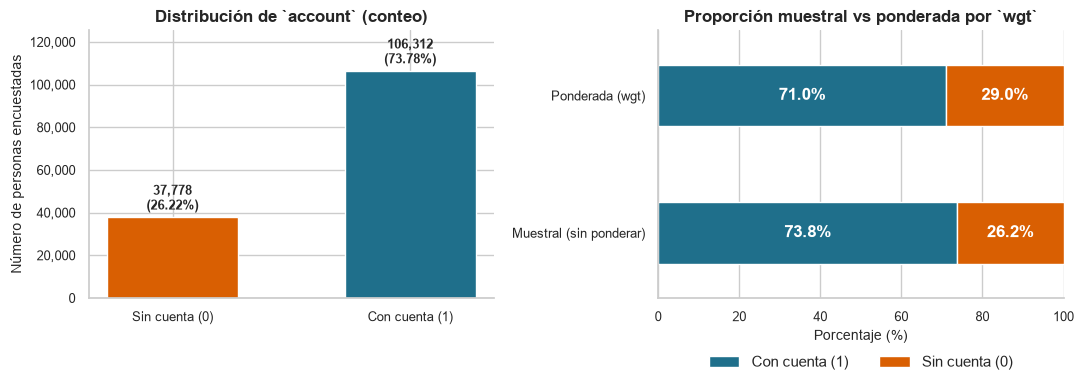

In [3]:
target_counts = df["account"].value_counts().sort_index()
target_pct = df["account"].value_counts(normalize=True).sort_index() * 100
tasa_ponderada_wgt = np.average(df["account"], weights=df["wgt"]) * 100

tabla_target = pd.DataFrame({
    "Clase": ["0 — Sin cuenta (No bancarizado)", "1 — Con cuenta (Bancarizado)"],
    "Frecuencia": target_counts.values,
    "Porcentaje (%)": target_pct.values.round(2),
})
display(tabla_target)
print(f"Tasa muestral sin ponderar con cuenta: {target_pct[1]:.2f}% | Ponderada por wgt: {tasa_ponderada_wgt:.2f}%")
print(f"Ratio de desbalance (clase 1 / clase 0): {target_counts[1] / target_counts[0]:.2f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# Conteos absolutos
bars = axes[0].bar(
    ["Sin cuenta (0)", "Con cuenta (1)"],
    target_counts.values,
    color=[COLOR_UNB, COLOR_ACC],
    width=0.55,
    edgecolor="white",
)
axes[0].set_title("Distribución de `account` (conteo)")
axes[0].set_ylabel("Número de personas encuestadas")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
axes[0].set_ylim(0, target_counts.max() * 1.18)
for bar, cnt, pct in zip(bars, target_counts.values, target_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1800,
        f"{cnt:,}\n({pct:.2f}%)",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold",
    )

# Barra apilada muestral vs ponderada
comparativa = pd.DataFrame({
    "Muestral (sin ponderar)": [target_pct[1], target_pct[0]],
    "Ponderada (wgt)": [tasa_ponderada_wgt, 100 - tasa_ponderada_wgt],
}, index=["Con cuenta (1)", "Sin cuenta (0)"]).T

comparativa.plot(
    kind="barh", stacked=True, ax=axes[1],
    color=[COLOR_ACC, COLOR_UNB], width=0.45, edgecolor="white"
)
axes[1].set_title("Proporción muestral vs ponderada por `wgt`")
axes[1].set_xlabel("Porcentaje (%)")
axes[1].set_xlim(0, 100)
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
for i, (con_v, sin_v) in enumerate(comparativa.values):
    axes[1].text(con_v / 2, i, f"{con_v:.1f}%", va="center", ha="center", color="white", fontweight="bold")
    axes[1].text(con_v + sin_v / 2, i, f"{sin_v:.1f}%", va="center", ha="center", color="white", fontweight="bold")

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


**Implicaciones para el modelado:**
- El dataset presenta un **desbalance moderado** (**73.78%** con cuenta frente a **26.22%** sin cuenta, ratio 2.81:1). Un clasificador ingenuo que predijese siempre `1` tendría 73.8% de accuracy sin detectar a ninguna persona excluida.
- Por ello se justifica plenamente usar `stratify=y` en el split 80/20, `class_weight="balanced"` en el baseline, y priorizar **F1, Recall (especialmente sobre la clase `0` no bancarizada si el objetivo de negocio es detectarla) y ROC-AUC**.


## 3. Análisis de valores nulos por columna

Al tratarse de una encuesta con preguntas condicionales (*skip logic*), muchas columnas `fin*` y `con*` solo se formulan a ciertos subgrupos (por ejemplo, preguntas sobre uso de tarjeta solo a quienes ya declararon tener cuenta, o barreras en `fin11*` solo a quienes no tienen cuenta). Analizamos primero las 199 columnas de forma global y luego en detalle las variables candidatas del perfil.


Columnas con 0% nulos (15): ['age', 'female', 'account_fin', 'account', 'pop_adult', 'wpid_random', 'wgt', 'regionwb', 'year', 'economy', 'economycode', 'fin2', 'internet_use', 'con1', 'con24']
Columnas con >0% a <15% nulos: {'fin46': 12.33, 'domestic_remittances': 8.2, 'emp_in': 2.79, 'urbanicity': 1.75, 'inc_q': 0.71, 'educ': 0.41}


,Número de columnas
0% (completas),15
>0% a <10%,5
10% a <50%,36
>=50% nulos,143


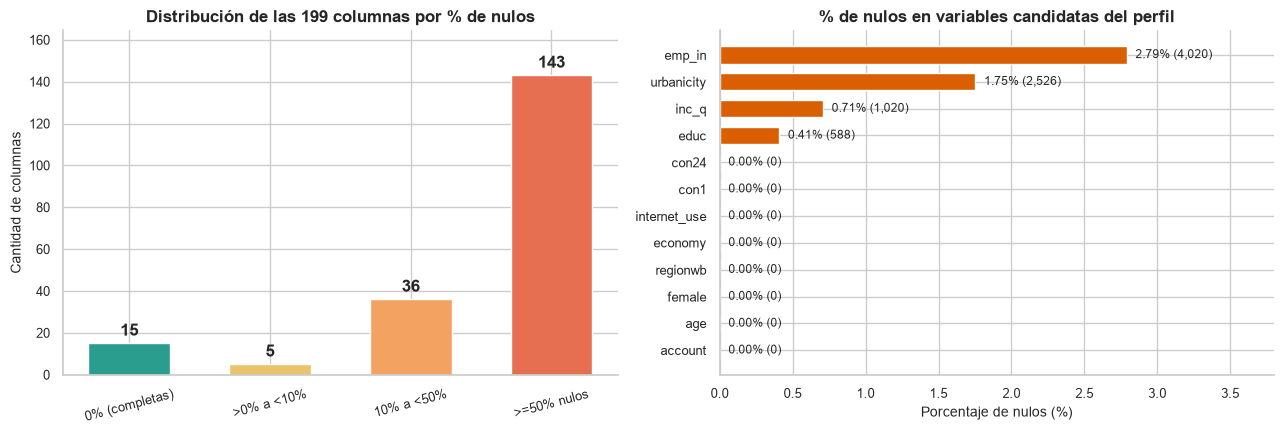

In [4]:
null_pct = (df.isna().mean() * 100).sort_values(ascending=False)
null_cnt = df.isna().sum()

tramos = pd.cut(
    null_pct,
    bins=[-0.01, 0.0, 10.0, 50.0, 100.0],
    labels=["0% (completas)", ">0% a <10%", "10% a <50%", ">=50% nulos"],
)
resumen_tramos = tramos.value_counts().sort_index()
display(resumen_tramos.to_frame("Número de columnas"))

print(f"Columnas con 0% nulos ({(null_pct == 0).sum()}):", list(null_pct[null_pct == 0].index))
print(f"Columnas con >0% a <15% nulos:", {c: round(float(null_pct[c]), 2) for c in null_pct[(null_pct > 0) & (null_pct < 15)].index})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Tramos en las 199 columnas
colors_tramos = ["#2a9d8f", "#e9c46a", "#f4a261", "#e76f51"]
bars_t = axes[0].bar(resumen_tramos.index.astype(str), resumen_tramos.values, color=colors_tramos, width=0.58)
axes[0].set_title("Distribución de las 199 columnas por % de nulos")
axes[0].set_ylabel("Cantidad de columnas")
axes[0].tick_params(axis="x", rotation=15)
axes[0].set_ylim(0, resumen_tramos.max() * 1.15)
for b in bars_t:
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f"{int(b.get_height())}",
                 ha="center", va="bottom", fontweight="bold")

# Detalle en variables candidatas del perfil + conectividad básica
cols_perfil_rev = [
    "account", "age", "female", "regionwb", "economy", "internet_use", "con1", "con24",
    "educ", "inc_q", "urbanicity", "emp_in"
]
perfil_nulls = (df[cols_perfil_rev].isna().mean() * 100).sort_values(ascending=True)
bar_cols = [COLOR_UNB if v > 0 else COLOR_ACC for v in perfil_nulls.values]
axes[1].barh(perfil_nulls.index, perfil_nulls.values, color=bar_cols, height=0.65)
axes[1].set_title("% de nulos en variables candidatas del perfil")
axes[1].set_xlabel("Porcentaje de nulos (%)")
axes[1].set_xlim(0, max(perfil_nulls.max() * 1.35, 3.8))
for i, (col_name, val) in enumerate(perfil_nulls.items()):
    cnt = int(null_cnt[col_name])
    axes[1].text(val + 0.06, i, f"{val:.2f}% ({cnt:,})", va="center", fontsize=8.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


In [5]:
# Patrón geográfico de los nulos en las 4 variables del perfil con missing
patrones_nulos = []
for col in ["emp_in", "urbanicity", "inc_q", "educ"]:
    mask = df[col].isna()
    econs = df.loc[mask, "economy"].value_counts()
    acc_null = df.loc[mask, "account"].mean() * 100
    patrones_nulos.append({
        "Columna": col,
        "Nulos totales": int(mask.sum()),
        "% Nulos": round(mask.mean() * 100, 2),
        "Economías afectadas": len(econs),
        "Top economías con nulos": ", ".join(f"{k} ({v})" for k, v in econs.head(3).items()),
        "% con cuenta en filas nulas": round(acc_null, 1),
    })
display(pd.DataFrame(patrones_nulos))


,Columna,Nulos totales,% Nulos,Economías afectadas,Top economías con nulos,% con cuenta en filas nulas
0,emp_in,4020,2.79,1,China (4020),88.5
1,urbanicity,2526,1.75,39,"China (378), Japan (198), Venezuela, RB (180)",90.1
2,inc_q,1020,0.71,1,Lesotho (1020),70.0
3,educ,588,0.41,104,"Comoros (54), South Africa (39), Oman (30)",63.6


**Hallazgo crítico para el preprocesado (`src/preprocess.py`):**
- **143 de 199 columnas** tienen **≥50% de nulos** por la estructura condicional del cuestionario; no son variables de perfil sino respuestas sobre productos o barreras financieras.
- En las variables de perfil, los nulos **no son aleatorios (MCAR)**:
  - **`emp_in`** (`4,020` nulos, `2.79%`): el **100% corresponde a China**.
  - **`inc_q`** (`1,020` nulos, `0.71%`): el **100% corresponde a Lesotho**.
  - **`urbanicity`** (`2,526` nulos, `1.75%`): afecta a 39 economías (incluyendo países desarrollados como Japón, Noruega, Países Bajos o Suecia), lo que explica que las filas con `urbanicity` nulo tengan un **90.1%** de bancarización.
  - **`educ`** (`588` nulos, `0.41%`): repartido en 104 economías.
- **Recomendación:** Evitar imputaciones globales ciegas en `urbanicity` o `emp_in` sin evaluar si conviene imputar por moda dentro de país/región o codificar una categoría explícita `"Desconocido"` (al menos para modelos basados en árboles) junto con indicadores de ausencia (`_is_missing`). Además, en `con1` (102 casos) y `con24` (298 casos) los códigos `3` y `4` (No sabe / No contesta) deben tratarse igual que los nulos antes de binarizar.


## 4. Histogramas y distribución de variables numéricas

Analizamos las variables cuantitativas (`age`, `pop_adult`, `wgt`) y la distribución de frecuencias de las variables ordinales (`educ`, `inc_q`), prestando especial atención a valores extremos y relación con `account`.


Conteo en edades >= 95: {95: 17, 96: 8, 97: 4, 98: 6, 99: 24, 100: 279}
En age == 100 (n=279), % con cuenta = 84.6% | Top países: {'Canada': 41, 'Australia': 40, 'New Zealand': 22, 'Ukraine': 10, 'Oman': 10}


,count,mean,std,min,25%,50%,75%,max
age,144090.0,43.07,1.808000e+01,15.00,28.00,40.00,57.00,1.000000e+02
pop_adult,144090.0,79784799.31,2.423602e+08,300138.00,4231057.00,9588258.00,33960981.00,1.176679e+09
wgt,144090.0,1.00,7.500000e-01,0.08,0.48,0.79,1.28,7.550000e+00
educ,143502.0,1.94,6.900000e-01,1.00,1.00,2.00,2.00,3.000000e+00
inc_q,143070.0,3.20,1.420000e+00,1.00,2.00,3.00,4.00,5.000000e+00


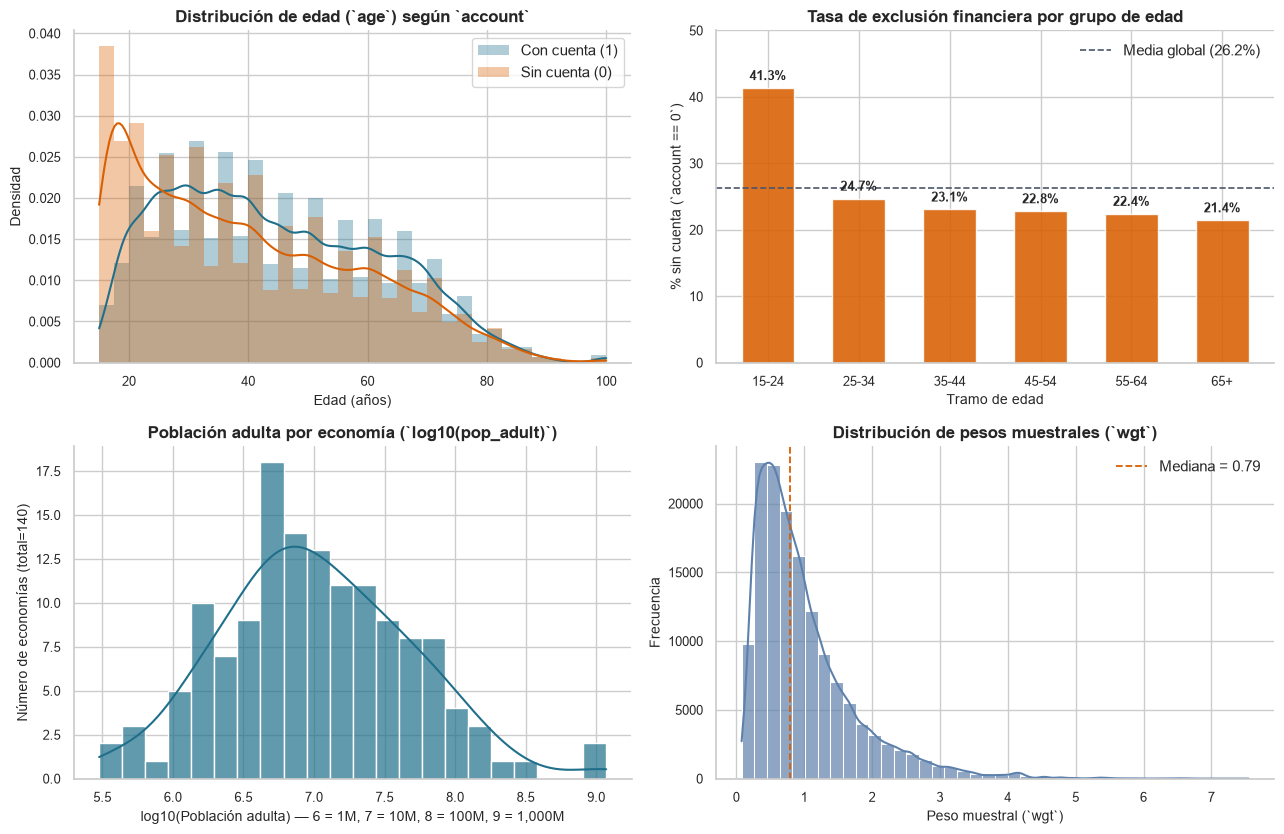

In [6]:
num_cols = ["age", "pop_adult", "wgt", "educ", "inc_q"]
desc = df[num_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]
display(desc.round(2))

# Inspección de cola superior de edad (posible top-coding)
top_ages = df[df["age"] >= 95]["age"].value_counts().sort_index()
print("Conteo en edades >= 95:", top_ages.to_dict())
print(f"En age == 100 (n={int((df['age']==100).sum())}), % con cuenta = {df.loc[df['age']==100, 'account'].mean()*100:.1f}% | Top países:",
      df.loc[df["age"] == 100, "economy"].value_counts().head(5).to_dict())

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))

# 1. Histograma + KDE de edad por clase del target
for val, lbl, col in [(1, "Con cuenta (1)", COLOR_ACC), (0, "Sin cuenta (0)", COLOR_UNB)]:
    sns.histplot(
        df.loc[df["account"] == val, "age"],
        bins=34, stat="density", kde=True,
        color=col, alpha=0.35, label=lbl, ax=axes[0, 0], edgecolor="none"
    )
axes[0, 0].set_title("Distribución de edad (`age`) según `account`")
axes[0, 0].set_xlabel("Edad (años)")
axes[0, 0].set_ylabel("Densidad")
axes[0, 0].legend(frameon=True)

# 2. Tasa de no bancarizados por tramos de edad
bins_age = [14, 24, 34, 44, 54, 64, 120]
labels_age = ["15-24", "25-34", "35-44", "45-54", "55-64", "65+"]
age_grp = pd.cut(df["age"], bins=bins_age, labels=labels_age)
age_stats = df.groupby(age_grp, observed=False)["account"].agg(n="count", acc="mean")
age_stats["unb_pct"] = (1 - age_stats["acc"]) * 100
bars_a = axes[0, 1].bar(age_stats.index.astype(str), age_stats["unb_pct"], color=COLOR_UNB, alpha=0.88, width=0.58)
axes[0, 1].axhline(26.22, color=COLOR_NEUTRAL, linestyle="--", linewidth=1.2, label="Media global (26.2%)")
axes[0, 1].set_title("Tasa de exclusión financiera por grupo de edad")
axes[0, 1].set_xlabel("Tramo de edad")
axes[0, 1].set_ylabel("% sin cuenta (`account == 0`)")
axes[0, 1].set_ylim(0, 50)
axes[0, 1].legend(frameon=False)
for b in bars_a:
    axes[0, 1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.8, f"{b.get_height():.1f}%",
                    ha="center", va="bottom", fontweight="bold", fontsize=9)

# 3. Histograma de población adulta por país (escala log10)
econ_pop = df.groupby("economy")["pop_adult"].first()
sns.histplot(np.log10(econ_pop), bins=22, kde=True, color=COLOR_ACC, alpha=0.7, ax=axes[1, 0])
axes[1, 0].set_title("Población adulta por economía (`log10(pop_adult)`)")
axes[1, 0].set_xlabel("log10(Población adulta) — 6 = 1M, 7 = 10M, 8 = 100M, 9 = 1,000M")
axes[1, 0].set_ylabel("Número de economías (total=140)")

# 4. Histograma del peso muestral wgt
sns.histplot(df["wgt"], bins=40, kde=True, color="#5e81ac", alpha=0.7, ax=axes[1, 1])
axes[1, 1].axvline(df["wgt"].median(), color=COLOR_UNB, linestyle="--", linewidth=1.3,
                   label=f"Mediana = {df['wgt'].median():.2f}")
axes[1, 1].set_title("Distribución de pesos muestrales (`wgt`)")
axes[1, 1].set_xlabel("Peso muestral (`wgt`)")
axes[1, 1].set_ylabel("Frecuencia")
axes[1, 1].legend(frameon=False)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


**Observaciones sobre las variables numéricas:**
- **`age`:** Media de **43.1 años** (mediana 40, rango 15–100). Las personas **jóvenes de 15 a 24 años** concentran la mayor exclusión con diferencia: **41.3%** sin cuenta, frente al **21.4%–24.7%** en todos los grupos de 25 años en adelante.
- **Anomalía de calidad en `age == 100`:** Hay **279 registros con exactamente 100 años** (frente a solo 6 con 98 y 24 con 99), concentrados en países como Canadá (41), Australia (40) y Nueva Zelanda (22). Indica un posible *top-coding* (edades mayores agrupadas en 100) o código de no respuesta en ciertos países; conviene tenerlo presente al crear tramos de edad.
- **`pop_adult`:** Muy asimétrica a la derecha (de 300 mil adultos en Islandia hasta 1,177 millones en India). Para modelos lineales requeriría transformación logarítmica, mientras `wgt` es una variable de diseño muestral y **no debe usarse como feature predictiva** del perfil de una persona en la app.


## 5. Matriz de correlación y verificación de Data Leakage

Para que los signos de correlación sean interpretables, primero recodificamos las variables del perfil a formato binario coherente (`1` = sí / presencia del atributo) y limpiamos los códigos `3` y `4` (NS/NC) de `con1` y `con24`. Luego analizamos:
1. La **matriz de correlación de Spearman** entre `account` y las variables limpias candidatas.
2. La **evidencia empírica de data leakage** (directo y estructural por patrón de nulos) en las columnas `fin*`, `account_*`, `dig_account`, etc.


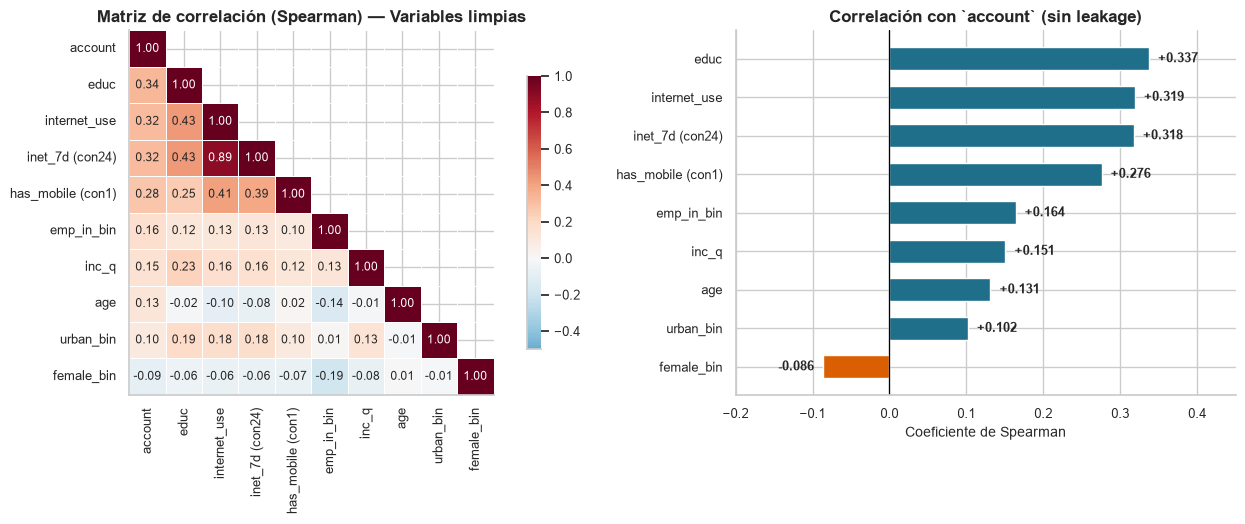

In [7]:
# DataFrame limpio de variables candidatas para correlación
df_corr = pd.DataFrame({
    "account": df["account"],
    "educ": df["educ"],
    "internet_use": df["internet_use"],
    "inet_7d (con24)": df["con24"].map({1: 1.0, 2: 0.0}),
    "has_mobile (con1)": df["con1"].map({1: 1.0, 2: 0.0}),
    "emp_in_bin": df["emp_in"].map({1: 1.0, 2: 0.0}),
    "inc_q": df["inc_q"],
    "age": df["age"],
    "urban_bin": df["urbanicity"].map({2: 1.0, 1: 0.0}),
    "female_bin": df["female"].map({1: 1.0, 2: 0.0}),
})

corr_spearman = df_corr.corr(method="spearman")
corr_target = corr_spearman["account"].drop("account").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.35, 1]})

# Heatmap triangular
mask = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)
sns.heatmap(
    corr_spearman, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-0.5, vmax=1.0, square=True, linewidths=0.5,
    cbar_kws={"shrink": 0.75}, ax=axes[0], annot_kws={"size": 8.5}
)
axes[0].set_title("Matriz de correlación (Spearman) — Variables limpias")

# Barras ordenadas frente a account
bar_colors = [COLOR_UNB if v < 0 else COLOR_ACC for v in corr_target.values]
axes[1].barh(corr_target.index, corr_target.values, color=bar_colors, height=0.6)
axes[1].axvline(0, color="black", linewidth=0.9)
axes[1].set_title("Correlación con `account` (sin leakage)")
axes[1].set_xlabel("Coeficiente de Spearman")
axes[1].set_xlim(-0.2, 0.45)
for i, val in enumerate(corr_target.values):
    offset = 0.012 if val >= 0 else -0.012
    ha = "left" if val >= 0 else "right"
    axes[1].text(val + offset, i, f"{val:+.3f}", va="center", ha=ha, fontsize=9, fontweight="bold")

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


In [8]:
# Evidencia de DATA LEAKAGE (correlaciones directas y leakage estructural por nulos)
leak_candidates = [
    "account_fin", "anydigpayment", "dig_account", "fin2", "account_mob",
    "merchantpay_dig", "receive_wages", "saved", "pay_utilities", "fin46", "borrowed"
]
leak_rows = []
for col in leak_candidates:
    corr_val = df[[col, "account"]].corr().iloc[0, 1]
    nn_1 = df.loc[df["account"] == 1, col].notna().mean() * 100
    nn_0 = df.loc[df["account"] == 0, col].notna().mean() * 100
    leak_rows.append({
        "Variable": col,
        "Corr Pearson con account": round(float(corr_val), 3),
        "% No nulo si account=1": round(nn_1, 1),
        "% No nulo si account=0": round(nn_0, 1),
    })
leak_df = pd.DataFrame(leak_rows).sort_values("Corr Pearson con account", key=lambda s: s.abs(), ascending=False)
display(leak_df)

# Variables cuyo patrón de nulos delata el target (>25 pp de diferencia)
struct_rows = []
for c in df.columns:
    if c.startswith(("fin", "con")):
        r1 = df.loc[df["account"] == 1, c].notna().mean() * 100
        r0 = df.loc[df["account"] == 0, c].notna().mean() * 100
        diff = abs(r1 - r0)
        if diff > 25:
            struct_rows.append({
                "Variable": c,
                "% No nulo (account=1)": round(r1, 1),
                "% No nulo (account=0)": round(r0, 1),
                "Diferencia (pp)": round(diff, 1),
            })
struct_df = pd.DataFrame(struct_rows).sort_values("Diferencia (pp)", ascending=False)
print(f"Total de variables fin*/con* con >25 pp de diferencia en presencia de nulos según target: {len(struct_df)}")
display(struct_df.head(12))


Total de variables fin*/con* con >25 pp de diferencia en presencia de nulos según target: 51


,Variable,Corr Pearson con account,% No nulo si account=1,% No nulo si account=0
0,account_fin,0.842,100.0,100.0
1,anydigpayment,0.818,63.1,94.8
2,dig_account,0.724,63.1,94.8
3,fin2,-0.631,100.0,100.0
4,account_mob,0.546,49.2,78.5
5,merchantpay_dig,0.486,63.1,94.8
6,receive_wages,-0.324,55.0,88.6
7,saved,0.312,63.1,94.8
8,pay_utilities,-0.287,55.0,88.6
9,fin46,-0.168,87.9,87.1


,Variable,% No nulo (account=1),% No nulo (account=0),Diferencia (pp)
8,fin11_0,1.3,55.3,54.0
10,fin11_2,1.3,55.3,54.0
9,fin11_1,1.3,55.3,54.0
16,fin11f,1.3,55.3,54.0
13,fin11c,1.3,55.3,54.0
12,fin11b,1.3,55.3,54.0
15,fin11e,1.3,55.3,54.0
14,fin11d,1.3,55.3,54.0
11,fin11a,1.3,55.3,54.0
39,fin25e2,60.5,9.4,51.2


**Conclusión sobre correlación y Data Leakage (para cerrar Fase 0):**
- **Variables más correlacionadas del perfil limpio:** `educ` (`+0.337`), `internet_use` (`+0.319`), `con24` (`+0.318`) y `con1` tener móvil (`+0.276`), seguidas de `emp_in` (`+0.164`), `inc_q` (`+0.151`), `age` (`+0.131`), `urbanicity` (`+0.102`) y `female` (`-0.086`, ser mujer se asocia con menor inclusión).
- **Alta colinealidad:** `internet_use` e `inet_7d` (`con24`) presentan una correlación de **0.89**; conviene probar si dejar solo `internet_use` simplifica la app y evita colinealidad en la regresión logística.
- **Data Leakage demostrado:**
  - **Directo:** `account_fin` (`r=+0.842`), `anydigpayment` (`r=+0.818`), `dig_account` (`r=+0.724`), `fin2` tarjeta de débito (`r=-0.631` por codificación 1/2), `account_mob` (`r=+0.546`), `merchantpay_dig` (`r=+0.486`).
  - **Estructural (por nulos):** **51 columnas `fin*`** delatan directamente el target por su patrón de respuesta: p. ej., `fin11a`–`fin11f` (razones de no tener cuenta) tienen datos en el **55.3%** de `account=0` frente al **1.3%** de `account=1`, y `fin3`, `fin4`, `fin8`, `fin9a`, `fin9b`, `fin10` existen en el **50.1%** de `account=1` y en el **0.0%** de `account=0`.
- **Lista recomendada de features limpias:** `age`, `female`, `educ`, `inc_q`, `emp_in`, `urbanicity`, `regionwb`, `internet_use`, `con1` (tenencia móvil), y evaluar `economy` (riesgo de overfitting por 140 categorías) vs `regionwb` + macroindicadores. **Excluir** todas las `fin*`, `account_fin`, `account_mob`, `dig_account`, `anydigpayment`, `saved`, `borrowed`, `receive_*`, `merchantpay_dig`, `pay_utilities`, `domestic_remittances`, `con2*`–`con32` (muchas son sub-preguntas condicionales), `wpid_random`, `wgt` y `year` (constante = 2024).


## 6. Target cruzado con género, ingreso, educación, región y variables clave

Analizamos la tasa de inclusión (`account == 1`) y exclusión (`account == 0`) en todos los ejes solicitados en `docs/TAREAS.md`, junto con conectividad digital, brecha de género por región y cruces bivariantes.


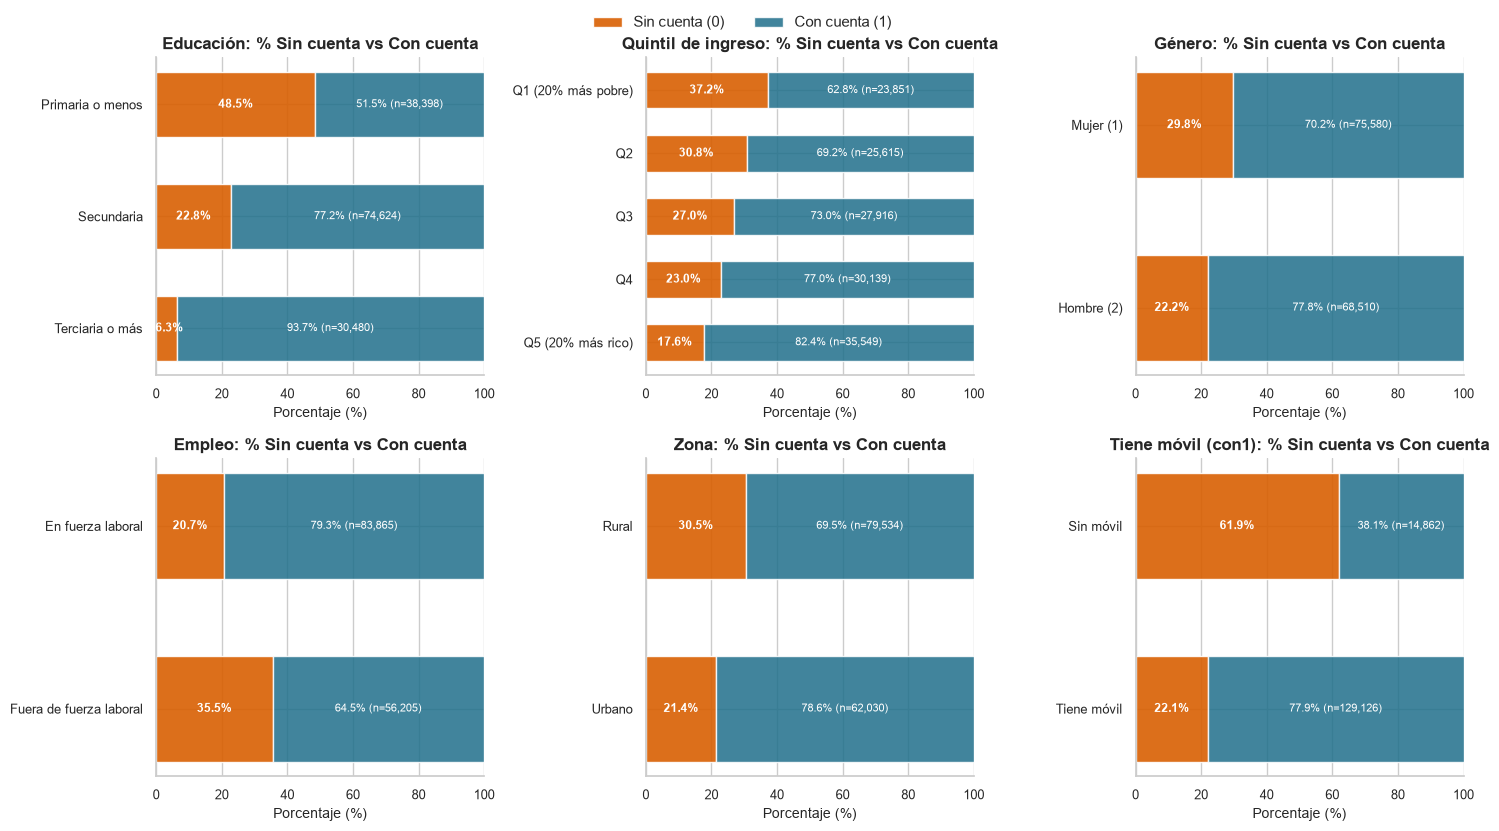

In [9]:
# Preparar etiquetas legibles para gráficos
plot_df = pd.DataFrame({
    "account": df["account"],
    "Género": df["female"].map({1: "Mujer (1)", 2: "Hombre (2)"}),
    "Educación": df["educ"].map({1: "Primaria o menos", 2: "Secundaria", 3: "Terciaria o más"}),
    "Quintil de ingreso": df["inc_q"].map({
        1: "Q1 (20% más pobre)", 2: "Q2", 3: "Q3", 4: "Q4", 5: "Q5 (20% más rico)"
    }),
    "Empleo": df["emp_in"].map({1: "En fuerza laboral", 2: "Fuera de fuerza laboral"}),
    "Zona": df["urbanicity"].map({1: "Rural", 2: "Urbano"}),
    "Uso de internet": df["internet_use"].map({1: "Usa internet", 0: "No usa internet"}),
    "Tiene móvil (con1)": df["con1"].map({1: "Tiene móvil", 2: "Sin móvil"}),
    "regionwb": df["regionwb"],
    "economy": df["economy"],
})

ejes = [
    ("Educación", ["Primaria o menos", "Secundaria", "Terciaria o más"]),
    ("Quintil de ingreso", ["Q1 (20% más pobre)", "Q2", "Q3", "Q4", "Q5 (20% más rico)"]),
    ("Género", ["Mujer (1)", "Hombre (2)"]),
    ("Empleo", ["En fuerza laboral", "Fuera de fuerza laboral"]),
    ("Zona", ["Rural", "Urbano"]),
    ("Tiene móvil (con1)", ["Sin móvil", "Tiene móvil"]),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, (col, order) in zip(axes.flat, ejes):
    stats = (
        plot_df.groupby(col)["account"]
        .agg(n="count", acc="mean")
        .reindex(order)
    )
    stats["unb_pct"] = (1 - stats["acc"]) * 100
    stats["acc_pct"] = stats["acc"] * 100

    y_pos = np.arange(len(stats))
    ax.barh(y_pos, stats["unb_pct"], color=COLOR_UNB, alpha=0.9, height=0.58, label="Sin cuenta (0)")
    ax.barh(y_pos, stats["acc_pct"], left=stats["unb_pct"], color=COLOR_ACC, alpha=0.85, height=0.58, label="Con cuenta (1)")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(stats.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_title(f"{col}: % Sin cuenta vs Con cuenta")
    ax.set_xlabel("Porcentaje (%)")
    for i, (u, a, n_obs) in enumerate(zip(stats["unb_pct"], stats["acc_pct"], stats["n"])):
        ax.text(max(u / 2, 4), i, f"{u:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=8.5)
        ax.text(u + a / 2, i, f"{a:.1f}% (n={n_obs:,})", va="center", ha="center", color="white", fontsize=8)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=10.5)
sns.despine(fig=fig)
plt.tight_layout()
plt.show()


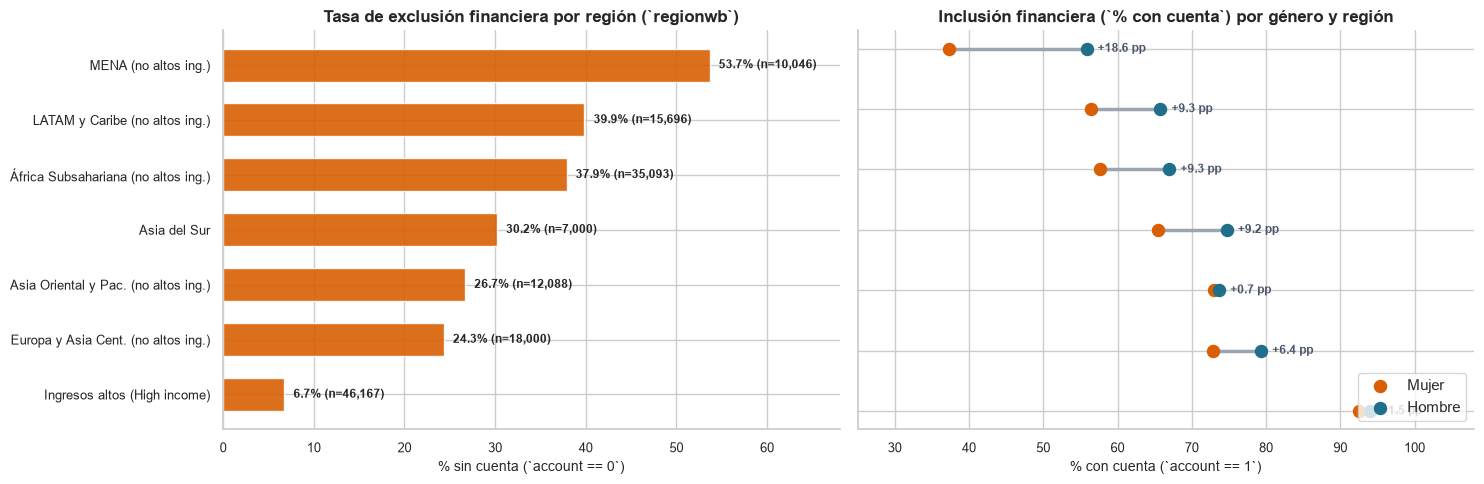

In [10]:
# Región (regionwb) y brecha de género por región
reg_short = {
    "Middle East & North Africa (excluding high income)": "MENA (no altos ing.)",
    "Latin America & Caribbean (excluding high income)": "LATAM y Caribe (no altos ing.)",
    "Sub-Saharan Africa (excluding high income)": "África Subsahariana (no altos ing.)",
    "South Asia": "Asia del Sur",
    "East Asia & Pacific (excluding high income)": "Asia Oriental y Pac. (no altos ing.)",
    "Europe & Central Asia (excluding high income)": "Europa y Asia Cent. (no altos ing.)",
    "High income": "Ingresos altos (High income)",
}
plot_df["region_corta"] = plot_df["regionwb"].map(reg_short)

reg_stats = plot_df.groupby("region_corta")["account"].agg(n="count", acc="mean")
reg_stats["unb_pct"] = (1 - reg_stats["acc"]) * 100
reg_stats = reg_stats.sort_values("unb_pct", ascending=True)

reg_fem = plot_df.groupby(["region_corta", "Género"])["account"].mean().unstack() * 100
reg_fem["Brecha (H - M pp)"] = reg_fem["Hombre (2)"] - reg_fem["Mujer (1)"]
reg_fem = reg_fem.loc[reg_stats.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Izquierda: % Sin cuenta por región
bars_r = axes[0].barh(reg_stats.index, reg_stats["unb_pct"], color=COLOR_UNB, alpha=0.9, height=0.6)
axes[0].set_title("Tasa de exclusión financiera por región (`regionwb`)")
axes[0].set_xlabel("% sin cuenta (`account == 0`)")
axes[0].set_xlim(0, 68)
for i, (val, n_obs) in enumerate(zip(reg_stats["unb_pct"], reg_stats["n"])):
    axes[0].text(val + 1.0, i, f"{val:.1f}% (n={n_obs:,})", va="center", fontsize=8.8, fontweight="bold")

# Derecha: Brecha de género por región (dumbbell chart)
y_idx = np.arange(len(reg_fem))
for i, reg_name in enumerate(reg_fem.index):
    w_val = reg_fem.loc[reg_name, "Mujer (1)"]
    m_val = reg_fem.loc[reg_name, "Hombre (2)"]
    gap = reg_fem.loc[reg_name, "Brecha (H - M pp)"]
    axes[1].plot([w_val, m_val], [i, i], color="#9aa5b1", linewidth=2.5, zorder=1)
    axes[1].text(max(w_val, m_val) + 1.5, i, f"+{gap:.1f} pp", va="center", fontsize=8.5, color=COLOR_NEUTRAL, fontweight="bold")

axes[1].scatter(reg_fem["Mujer (1)"], y_idx, color=COLOR_UNB, s=75, label="Mujer", zorder=2)
axes[1].scatter(reg_fem["Hombre (2)"], y_idx, color=COLOR_ACC, s=75, label="Hombre", zorder=2)
axes[1].set_yticks(y_idx)
axes[1].set_yticklabels([])
axes[1].set_xlim(25, 108)
axes[1].set_title("Inclusión financiera (`% con cuenta`) por género y región")
axes[1].set_xlabel("% con cuenta (`account == 1`)")
axes[1].legend(loc="lower right", frameon=True)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


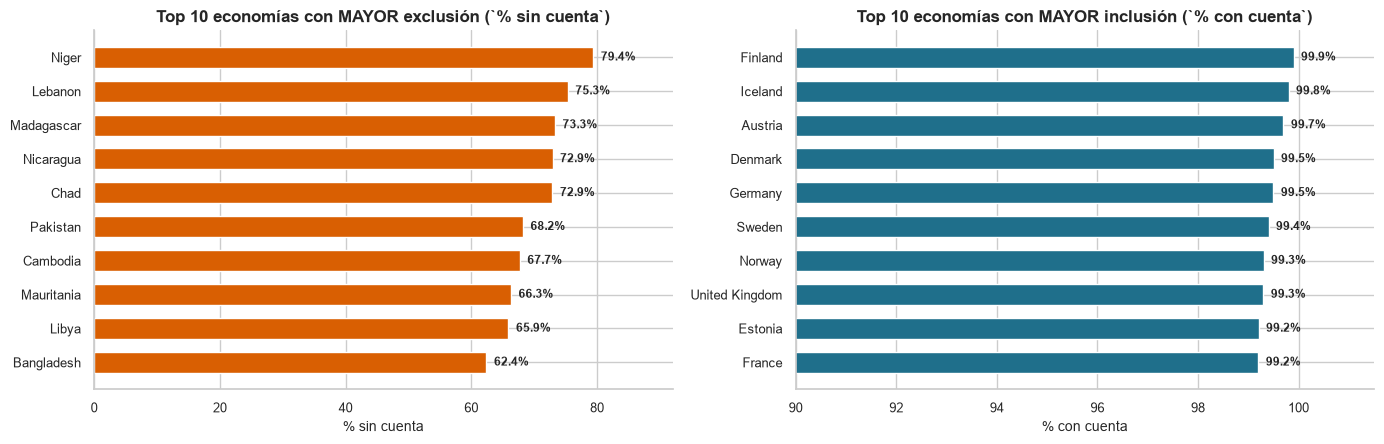

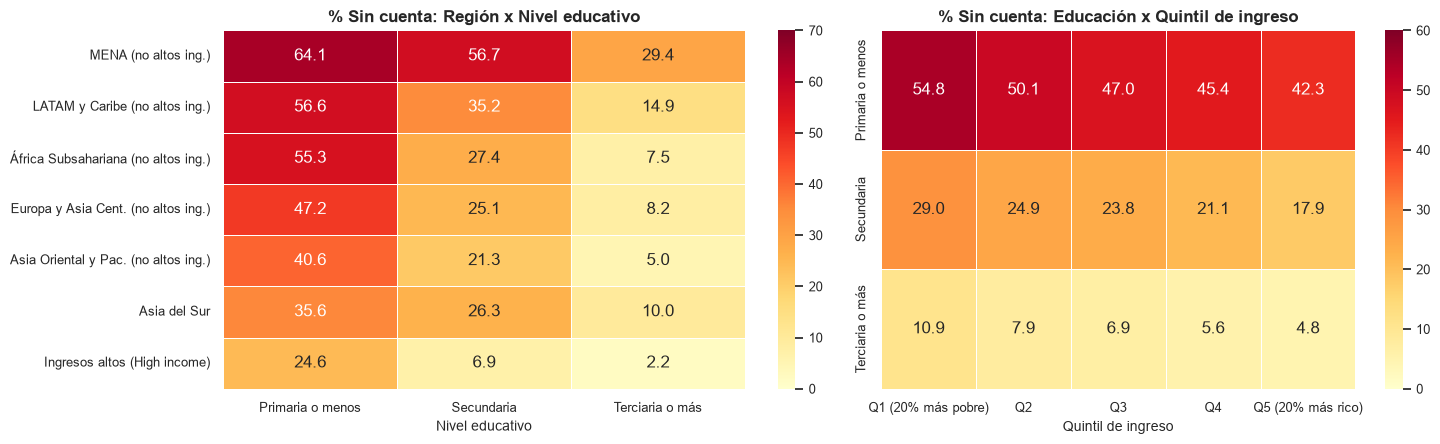

In [11]:
# Top 10 economías con mayor exclusión vs mayor inclusión + Heatmaps de interacción 2D
econ_stats = df.groupby(["economy", "regionwb"])["account"].agg(n="count", acc="mean").reset_index()
econ_stats["unb_pct"] = (1 - econ_stats["acc"]) * 100
econ_stats["acc_pct"] = econ_stats["acc"] * 100

top10_excl = econ_stats.sort_values("unb_pct", ascending=False).head(10).sort_values("unb_pct", ascending=True)
top10_incl = econ_stats.sort_values("acc_pct", ascending=False).head(10).sort_values("acc_pct", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].barh(top10_excl["economy"], top10_excl["unb_pct"], color=COLOR_UNB, height=0.62)
axes[0].set_title("Top 10 economías con MAYOR exclusión (`% sin cuenta`)")
axes[0].set_xlabel("% sin cuenta")
axes[0].set_xlim(0, 92)
for i, v in enumerate(top10_excl["unb_pct"]):
    axes[0].text(v + 1.2, i, f"{v:.1f}%", va="center", fontsize=8.8, fontweight="bold")

axes[1].barh(top10_incl["economy"], top10_incl["acc_pct"], color=COLOR_ACC, height=0.62)
axes[1].set_title("Top 10 economías con MAYOR inclusión (`% con cuenta`)")
axes[1].set_xlabel("% con cuenta")
axes[1].set_xlim(90, 101.5)
for i, v in enumerate(top10_incl["acc_pct"]):
    axes[1].text(v + 0.15, i, f"{v:.1f}%", va="center", fontsize=8.8, fontweight="bold")

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

# Heatmaps de interacción (% sin cuenta)
hm_reg_educ = (1 - plot_df.groupby(["region_corta", "Educación"])["account"].mean()).unstack() * 100
hm_reg_educ = hm_reg_educ[["Primaria o menos", "Secundaria", "Terciaria o más"]].sort_values("Primaria o menos", ascending=False)

hm_inc_educ = (1 - plot_df.groupby(["Educación", "Quintil de ingreso"])["account"].mean()).unstack() * 100
hm_inc_educ = hm_inc_educ.loc[
    ["Primaria o menos", "Secundaria", "Terciaria o más"],
    ["Q1 (20% más pobre)", "Q2", "Q3", "Q4", "Q5 (20% más rico)"]
]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(hm_reg_educ, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=70, ax=axes[0], linewidths=0.5)
axes[0].set_title("% Sin cuenta: Región x Nivel educativo")
axes[0].set_ylabel("")
axes[0].set_xlabel("Nivel educativo")

sns.heatmap(hm_inc_educ, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=60, ax=axes[1], linewidths=0.5)
axes[1].set_title("% Sin cuenta: Educación x Quintil de ingreso")
axes[1].set_ylabel("")
axes[1].set_xlabel("Quintil de ingreso")

plt.tight_layout()
plt.show()


**Hallazgos clave de los cruces bivariantes y multivariantes:**
- **La educación domina sobre el ingreso:** Una persona con educación primaria o menos en el quintil más rico (`Q5`) sigue teniendo un **42.3%** de exclusión financiera, cuatro veces más que una persona con educación terciaria en el quintil más pobre (`Q1`, **10.9%**).
- **Brecha de género heterogénea:** Globalmente las mujeres tienen **7.6 pp** menos inclusión (70.2% vs 77.8% en hombres), pero esa brecha se dispara a **18.6 pp** en MENA (37.3% vs 55.8%) y supera los **9 pp** en África Subsahariana, América Latina y Asia del Sur, mientras casi desaparece en Asia Oriental y Pacífico (0.7 pp) y High income (1.5 pp).
- **Concentración geográfica:** El **91.8%** de los no bancarizados (`34,663` de `37,778`) vive fuera de economías de ingresos altos. Las economías con mayor exclusión alcanzan cifras del 62%–79% (Níger, Líbano, Madagascar, Nicaragua, Chad, Pakistán).


## 7. Insights de negocio: perfiles de riesgo, volumen y oportunidad digital

Para diseñar campañas de inclusión financiera no basta saber qué grupo tiene la tasa más alta de exclusión (*riesgo*); también hay que medir **qué proporción de las 37,778 personas no bancarizadas representa** (*volumen*) y **qué canal digital tienen disponible** para llegar a ellas.


,Segmento,Muestra (n),No bancarizados (n),Tasa exclusión (%),% del total no bancarizado
0,Sin teléfono móvil (con1=2),14862,9205,61.9,24.4
1,Educación primaria + Rural,26572,13604,51.2,36.0
2,Sin uso de internet,35529,18028,50.7,47.7
3,Educación primaria o menos,38398,18626,48.5,49.3
4,Jóvenes (15-24 años),25252,10438,41.3,27.6
5,Mujer fuera de fuerza laboral,36092,14092,39.0,37.3
6,Fuera de fuerza laboral,56205,19948,35.5,52.8
7,40% más pobre (Q1 y Q2),49466,16750,33.9,44.3
8,Zona rural,79534,24240,30.5,64.2
9,Mujeres,75580,22539,29.8,59.7


,Personas sin cuenta,% de los no bancarizados
Móvil + Internet (Digital-ready),18341,48.55
"Solo móvil, sin internet (USSD/SMS)",10191,26.98
Sin móvil ni internet (Desconectado),7812,20.68
Internet sin móvil propio,1393,3.69
NS/NC en con1,41,0.11


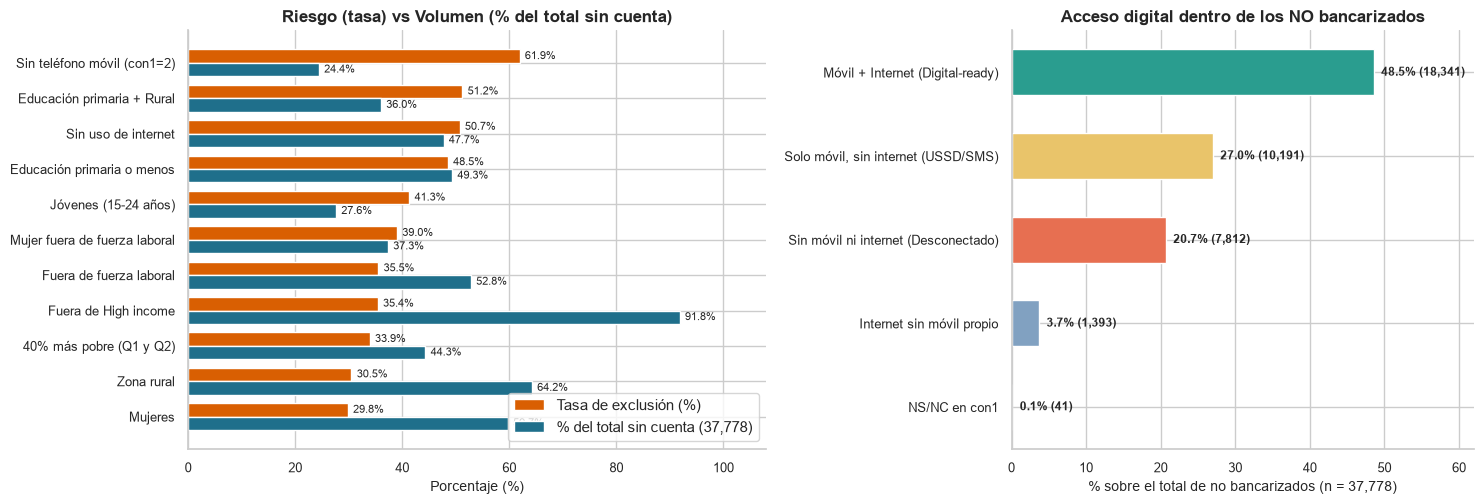

In [12]:
unb = df[df["account"] == 0]
n_unb = len(unb)

segmentos = [
    ("Sin teléfono móvil (con1=2)", df["con1"] == 2),
    ("Educación primaria + Rural", (df["educ"] == 1) & (df["urbanicity"] == 1)),
    ("Sin uso de internet", df["internet_use"] == 0),
    ("Educación primaria o menos", df["educ"] == 1),
    ("Jóvenes (15-24 años)", df["age"] <= 24),
    ("Mujer fuera de fuerza laboral", (df["female"] == 1) & (df["emp_in"] == 2)),
    ("Fuera de fuerza laboral", df["emp_in"] == 2),
    ("40% más pobre (Q1 y Q2)", df["inc_q"].isin([1, 2])),
    ("Zona rural", df["urbanicity"] == 1),
    ("Mujeres", df["female"] == 1),
    ("Fuera de High income", df["regionwb"] != "High income"),
]

seg_rows = []
for nombre, mask in segmentos:
    sub = df[mask]
    unb_sub = int((sub["account"] == 0).sum())
    seg_rows.append({
        "Segmento": nombre,
        "Muestra (n)": len(sub),
        "No bancarizados (n)": unb_sub,
        "Tasa exclusión (%)": round(100 * unb_sub / len(sub), 1),
        "% del total no bancarizado": round(100 * unb_sub / n_unb, 1),
    })
seg_df = pd.DataFrame(seg_rows)
display(seg_df)

# Conectividad digital DENTRO de las personas no bancarizadas (account == 0)
cat_digital = pd.Series(index=unb.index, dtype="object")
has_mob = unb["con1"] == 1
no_mob = unb["con1"] == 2
has_inet = unb["internet_use"] == 1
no_inet = unb["internet_use"] == 0

cat_digital[has_mob & has_inet] = "Móvil + Internet (Digital-ready)"
cat_digital[has_mob & no_inet] = "Solo móvil, sin internet (USSD/SMS)"
cat_digital[no_mob & has_inet] = "Internet sin móvil propio"
cat_digital[no_mob & no_inet] = "Sin móvil ni internet (Desconectado)"
cat_digital = cat_digital.fillna("NS/NC en con1")

dig_counts = cat_digital.value_counts()
dig_pct = (dig_counts / n_unb * 100).round(2)
display(pd.DataFrame({"Personas sin cuenta": dig_counts, "% de los no bancarizados": dig_pct}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})

# Riesgo vs Volumen
seg_plot = seg_df.sort_values("Tasa exclusión (%)", ascending=True)
y_s = np.arange(len(seg_plot))
h = 0.38
axes[0].barh(y_s + h/2, seg_plot["Tasa exclusión (%)"], height=h, color=COLOR_UNB, label="Tasa de exclusión (%)")
axes[0].barh(y_s - h/2, seg_plot["% del total no bancarizado"], height=h, color=COLOR_ACC, label="% del total sin cuenta (37,778)")
axes[0].set_yticks(y_s)
axes[0].set_yticklabels(seg_plot["Segmento"])
axes[0].set_xlim(0, 108)
axes[0].set_xlabel("Porcentaje (%)")
axes[0].set_title("Riesgo (tasa) vs Volumen (% del total sin cuenta)")
axes[0].legend(loc="lower right", frameon=True)
for i, (r_val, v_val) in enumerate(zip(seg_plot["Tasa exclusión (%)"], seg_plot["% del total no bancarizado"])):
    axes[0].text(r_val + 1, i + h/2, f"{r_val:.1f}%", va="center", fontsize=8)
    axes[0].text(v_val + 1, i - h/2, f"{v_val:.1f}%", va="center", fontsize=8)

# Canal digital entre no bancarizados
orden_dig = [
    "Móvil + Internet (Digital-ready)",
    "Solo móvil, sin internet (USSD/SMS)",
    "Sin móvil ni internet (Desconectado)",
    "Internet sin móvil propio",
    "NS/NC en con1",
]
dig_ordered = dig_pct.reindex([o for o in orden_dig if o in dig_pct.index])
pal_dig = ["#2a9d8f", "#e9c46a", "#e76f51", "#81a1c1", "#b0b0b0"][:len(dig_ordered)]
bars_d = axes[1].barh(dig_ordered.index, dig_ordered.values, color=pal_dig, height=0.55)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 62)
axes[1].set_xlabel("% sobre el total de no bancarizados (n = 37,778)")
axes[1].set_title("Acceso digital dentro de los NO bancarizados")
for i, (lbl, pct_v) in enumerate(dig_ordered.items()):
    cnt_v = int(dig_counts[lbl])
    axes[1].text(pct_v + 1, i, f"{pct_v:.1f}% ({cnt_v:,})", va="center", fontsize=8.8, fontweight="bold")

sns.despine(fig=fig)
plt.tight_layout()
plt.show()


## 8. Resumen de insights de negocio y handoff técnico

### Tres palancas accionables para inclusión financiera
1. **Onboarding digital inmediato (*Mobile + Internet*, 48.6% de los no bancarizados — 18,341 personas):** Casi la mitad de las personas sin cuenta ya tiene teléfono móvil y usa internet, y el **75.5%** (28,532) tiene móvil propio. Es el segmento prioritario para billeteras móviles, apertura de cuentas 100% online y KYC simplificado, especialmente enfocado en **jóvenes de 15–24 años** (41.3% de exclusión).
2. **Banca móvil sin datos y redes de agentes (*Solo móvil sin internet*, 27.0% — 10,191 personas):** Más de un cuarto de los no bancarizados posee móvil pero no internet. Campañas vía **USSD/SMS** y corresponsales locales permiten capturar este volumen en **zonas rurales** (64.2% de todos los no bancarizados).
3. **Inclusión presencial, alfabetización y enfoque de género (*Sin móvil ni internet*, 20.7% — 7,812 personas):** Concentrado en personas con **educación primaria o menos** (49.3% de todo el universo no bancarizado) y **mujeres fuera de la fuerza laboral** (37.3% del total). Requiere educación financiera básica, productos sin comisiones mínimas y agentes comunitarios, con foco prioritario en **MENA** (18.6 pp de brecha de género), **África Subsahariana**, **LATAM** y **Asia del Sur**.

### Notas técnicas para el equipo (Fase 0, `src/preprocess.py` y Modelado)
- **Alineación con `src/preprocess.py` (Franco, ya integrado en `dev`):**
  - La lista blanca implementada (`age`, `educ`, `inc_q`, `female`, `emp_in`, `urbanicity` -> `urban`, `internet_use`, `regionwb`, `economycode`) excluye correctamente todas las columnas con leakage (`fin*`, `con*`, `account_*`, `dig_account`, `anydigpayment`, `saved`, `borrowed`, `receive_*`, `pay_*`, `merchantpay_dig`, `domestic_remittances`) y de diseño (`wpid_random`, `wgt`, `year`, `pop_adult`).
  - La recodificación `1/2 -> 1/0` (`female`, `emp_in`, `urbanicity -> urban`) y los indicadores de valores faltantes en binarias (`add_indicator=True`, capturando p. ej. `emp_in` nulo = China) coinciden con lo observado en este EDA.
- **Puntos de atención para iteraciones y Modelado (Tania):**
  - **Candidata adicional sin leakage:** `con1` (tenencia de móvil, `r = +0.276`, 0% nulos salvo 102 casos con códigos `3/4` NS/NC) es una señal fuerte que podría probarse en una v2 del pipeline.
  - **`inc_q` en Lesotho:** los 1,020 nulos (0.71%) corresponden íntegramente a Lesotho (la mediana global imputada en `preprocess.py` asigna quintil 3; conviene monitorear).
  - **`age == 100`:** existen 279 registros con edad 100 (posible *top-coding* en algunos países).
  - **Riesgo de overfitting con `economycode`:** añade ~140 columnas one-hot; vigilar la brecha de F1 entre train y test (< 5%) frente a entrenar solo con `regionwb`.
  - **Desbalance del target:** 73.78% / 26.22% -> usar `class_weight="balanced"` y reportar F1, Recall (especialmente clase `0`) y ROC-AUC; tener en cuenta que `internet_use` y `con24` tienen `r = 0.89`.
